# Linear static analysis

A simply supported rectangular isotropic plate under two transverse loads: a
uniform pressure and a point load at the centre. In both cases the stiffness
matrix is assembled with `update_KC0`, the linear system
$\boldsymbol{K}_{C0}\boldsymbol{u} = \boldsymbol{F}_{ext}$ is solved for the
unconstrained degrees of freedom, and the deflection at the centre is
compared with the series solutions of the classical plate theory of
Timoshenko and Woinowsky-Krieger [1]. The same models are checked in
`tests/test_static_pressure.py` and `tests/test_static_point_load.py`.

Units: N, m, Pa.

In [1]:
%matplotlib inline
import numpy as np
from numpy import isclose
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt
from composites import isotropic_plate

from bfscplate2d import (BFSCPlate2D, update_KC0, DOF, KC0_SPARSE_SIZE, DOUBLE,
        INT)
from bfscplate2d.quadrature import get_points_weights

## Theory

For small displacements the equilibrium is

$$
\boldsymbol{K}_{C0} \boldsymbol{u} = \boldsymbol{F}_{ext}
$$

restricted to the unconstrained degrees of freedom. $\boldsymbol{K}_{C0}$ is
symmetric and positive definite once the rigid-body motions are constrained.
For the isotropic plate $\boldsymbol{B} = \boldsymbol{0}$: the membrane and
bending problems are uncoupled, and a transverse load gives no membrane
forces.

Each node has the degrees of freedom $u$, $u_{,x}$, $u_{,y}$, $v$, $v_{,x}$,
$v_{,y}$, $w$, $w_{,x}$, $w_{,y}$, $w_{,xy}$, at the positions 0 to 9 of
`DOF = 10`. Along an edge $x$ = constant the interpolated $w$ depends only
on $w$ and $w_{,y}$ at the two nodes of the edge, so $w = 0$ on the whole
edge needs both nodal values constrained ($w$ and $w_{,x}$ on an edge $y$ =
constant). The normal slope and $w_{,xy}$ stay free, also at the corners,
which gives the simply supported plate.

## Mesh and stiffness matrix

The plate has sides $a$ along $x$ and $b$ along $y$ and is meshed with
`nx` by `ny` nodes. The function below builds the elements of a regular mesh
and assembles $\boldsymbol{K}_{C0}$ with `nint = 4` integration points along
$\xi$ and $\eta$; it is used for the two meshes of this example.

In [2]:
def build_plate(nx, ny, a, b, lam):
    points, weights = get_points_weights(nint=4)

    xtmp = np.linspace(0, a, nx)
    ytmp = np.linspace(0, b, ny)
    xmesh, ymesh = np.meshgrid(xtmp, ytmp)

    # node coordinates and position in the global matrix
    ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten())).T
    nids = 1 + np.arange(ncoords.shape[0])
    nid_pos = dict(zip(nids, np.arange(len(nids))))
    nids_mesh = nids.reshape(nx, ny)

    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()
    num_elements = len(n1s)

    N = DOF*nx*ny
    Kr = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=INT)
    Kc = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=INT)
    Kv = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    init_k_KC0 = 0

    plates = []
    for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
        plate = BFSCPlate2D()
        plate.c1 = DOF*nid_pos[n1]
        plate.c2 = DOF*nid_pos[n2]
        plate.c3 = DOF*nid_pos[n3]
        plate.c4 = DOF*nid_pos[n4]
        plate.ABD = lam.ABD
        plate.lex = a/(nx - 1)
        plate.ley = b/(ny - 1)
        plate.init_k_KC0 = init_k_KC0
        update_KC0(plate, points, weights, Kr, Kc, Kv)
        init_k_KC0 += KC0_SPARSE_SIZE
        plates.append(plate)

    KC0 = coo_matrix((Kv, (Kr, Kc)), shape=(N, N)).tocsc()
    return KC0, plates, ncoords[:, 0], ncoords[:, 1], xmesh, ymesh


def print_table(rows):
    print('%-32s %14s %14s %10s' % ('quantity', 'computed', 'reference',
                                    'diff (%)'))
    for name, value, ref in rows:
        print('%-32s %14.6e %14.6e %+10.4f' % (name, value, ref,
                                               100*(value - ref)/ref))

## Plate under a uniform pressure

The plate of $a = 3$ m by $b = 7$ m, thickness $h = 5$ mm, $E = 200$ GPa,
$\nu = 0.3$, is meshed with 5 by 7 nodes (4 by 6 elements).

In [3]:
nx = 5
ny = 7
a = 3
b = 7
E = 200e9
nu = 0.3
h = 0.005
lam = isotropic_plate(thickness=h, E=E, nu=nu)

KC0, plates, x, y, xmesh, ymesh = build_plate(nx, ny, a, b, lam)
print('num_elements', len(plates))
print('degrees of freedom', KC0.shape[0])

num_elements 24
degrees of freedom 350


The edges are simply supported as described above, $w$ and its derivative
along the edge at the nodes of the four edges; $u$ and $v$ are constrained
at the central node, the membrane problem being unloaded and uncoupled from
the bending problem.

In [4]:
bk = np.zeros(KC0.shape[0], dtype=bool)

# simply supported: w and its derivative along the edge
edges_x = isclose(x, 0) | isclose(x, a)
edges_y = isclose(y, 0) | isclose(y, b)
bk[6::DOF] = edges_x | edges_y
bk[8::DOF] = edges_x
bk[7::DOF] = edges_y
# point supports (middle)
check = isclose(x, a/2) & isclose(y, b/2)
bk[0::DOF] = check
bk[3::DOF] = check

bu = ~bk

The consistent force vector of the pressure $P$ is

$$
\boldsymbol{F}_{ext} = \int_A P \, (\boldsymbol{S}^w)^\top dA
$$

computed element by element with `nint = 4` Gauss points along $\xi$ and
$\eta$, exact for the bicubic rows $\boldsymbol{S}^w$ of
`BFSCPlate2D.update_Sw`; $dA = (\ell_{ex} \ell_{ey}/4)\, d\xi\, d\eta$.
The function is used again below for the second set of boundary
conditions.

In [5]:
def pressure_load(plates, N, P, nint=4):
    points, weights = get_points_weights(nint)
    f = np.zeros(N, dtype=float)
    for plate in plates:
        indices = []
        for ci in [plate.c1, plate.c2, plate.c3, plate.c4]:
            for i in range(DOF):
                indices.append(ci + i)
        fe = np.zeros(4*DOF, dtype=float)
        for i in range(nint):
            for j in range(nint):
                weight = weights[i]*weights[j]
                plate.update_Sw(points[i], points[j])
                Sw = np.asarray(plate.Sw)
                fe += (plate.lex*plate.ley)/4*weight*Sw*P
        f[indices] += fe
    return f


P = 10 # Pa
f = pressure_load(plates, KC0.shape[0], P)
print('sum of the w entries of the force vector', f[6::DOF].sum())
print('P a b', P*a*b)

sum of the w entries of the force vector 210.0
P a b 210


Solving the partitioned system:

In [6]:
Kuu = KC0[bu, :][:, bu]
fu = f[bu]
uu = spsolve(Kuu, fu)
u = np.zeros(KC0.shape[0], dtype=float)
u[bu] = uu

w = u[6::DOF].reshape(nx, ny).T
print('wmax', w.max())
print('wmin', w.min())

wmax 0.003937291925011881
wmin 0.0


### Navier solution

The Navier double-series solution of the simply supported rectangular plate
under a uniform pressure gives the deflection at the centre [1]

$$
w_{max} = \frac{16 P}{\pi^6 D} \sum_{m = 1, 3, ...} \sum_{n = 1, 3, ...}
\frac{\sin(m \pi/2) \sin(n \pi/2)}{m n \left( m^2/a^2 + n^2/b^2 \right)^2},
\qquad D = \frac{E h^3}{12 (1 - \nu^2)}
$$

summed below with the terms up to $m = n = 199$.

In [7]:
D = E*h**3/(12*(1 - nu**2))
ms = np.arange(1, 200, 2)
mm, nn = np.meshgrid(ms, ms)
w_navier = 16*P/(np.pi**6*D)*np.sum(
    np.sin(mm*np.pi/2)*np.sin(nn*np.pi/2)
    /(mm*nn*(mm**2/a**2 + nn**2/b**2)**2))

print_table([('w_max, pressure (m)', w.max(), w_navier)])

quantity                               computed      reference   diff (%)
w_max, pressure (m)                3.937292e-03   3.937198e-03    +0.0024


The force vector sums to the total load $P a b = 210$ N. The maximum
deflection, at the centre, is $3.937292 \times 10^{-3}$ m with 4 by 6
elements, 0.0024 % above the Navier solution $3.937198 \times 10^{-3}$ m.

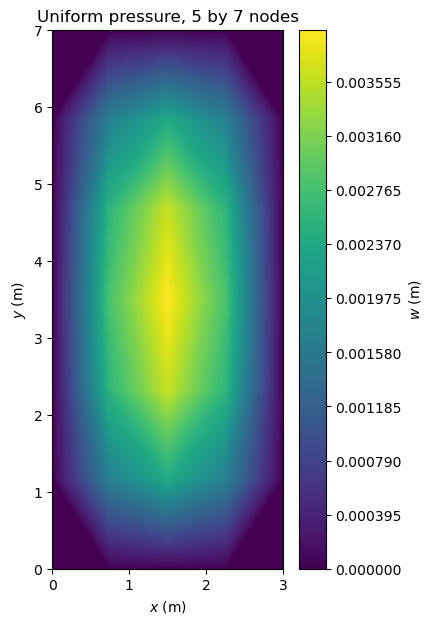

In [8]:
plt.figure(figsize=(4, 7))
plt.gca().set_aspect('equal')
levels = np.linspace(w.min(), w.max(), 300)
plt.contourf(xmesh, ymesh, w, levels=levels)
plt.colorbar(label='$w$ (m)')
plt.xlabel('$x$ (m)')
plt.ylabel('$y$ (m)')
plt.title('Uniform pressure, 5 by 7 nodes')
plt.show()

### Constraining $w$ only at the nodes of the edges

If only $w$ is constrained at the nodes of the edges, the interpolated $w$
is zero at these nodes but not between them, where $w_{,y}$ (edges $x$ =
constant) or $w_{,x}$ (edges $y$ = constant) of the nodes make it
nonzero. The function below samples $w$ along the sides of the elements that
lie on the edges of the plate with `BFSCPlate2D.update_Sw` at $\xi = \pm 1$
or $\eta = \pm 1$ (node 1 is at $\xi = \eta = -1$, node 2 along $+x$, node 4
along $+y$) and returns the maximum $|w|$. The same model is then solved
with $w$ alone constrained at the nodes of the edges.

In [9]:
def max_w_edges(plates, u, x, y, a, b, nsample=41):
    s = np.linspace(-1, 1, nsample)
    wmax = 0.
    for plate in plates:
        cs = [plate.c1, plate.c2, plate.c3, plate.c4]
        ue = np.concatenate([u[c:c+DOF] for c in cs])
        i1, i2, i4 = plate.c1//DOF, plate.c2//DOF, plate.c4//DOF
        pts = []
        if isclose(x[i1], 0):
            pts += [(-1., eta) for eta in s]
        if isclose(x[i2], a):
            pts += [(1., eta) for eta in s]
        if isclose(y[i1], 0):
            pts += [(xi, -1.) for xi in s]
        if isclose(y[i4], b):
            pts += [(xi, 1.) for xi in s]
        for xi, eta in pts:
            plate.update_Sw(xi, eta)
            wmax = max(wmax, abs(np.asarray(plate.Sw) @ ue))
    return wmax


# w only at the nodes of the edges
bk_w = np.zeros(KC0.shape[0], dtype=bool)
bk_w[6::DOF] = edges_x | edges_y
bk_w[0::DOF] = check
bk_w[3::DOF] = check
bu_w = ~bk_w

u_w = np.zeros(KC0.shape[0], dtype=float)
u_w[bu_w] = spsolve(KC0[bu_w, :][:, bu_w], f[bu_w])
w_w = u_w[6::DOF].reshape(nx, ny).T

print('%-28s %14s %10s %18s' % ('edges', 'w_max (m)', 'diff (%)',
                                'max|w| edges/w_max'))
for name, ui, wi in [('w and tangential derivative', u, w),
                     ('w only', u_w, w_w)]:
    print('%-28s %14.6e %+10.4f %18.4e' % (name, wi.max(),
          100*(wi.max() - w_navier)/w_navier,
          max_w_edges(plates, ui, x, y, a, b)/wi.max()))

edges                             w_max (m)   diff (%) max|w| edges/w_max
w and tangential derivative    3.937292e-03    +0.0024         0.0000e+00
w only                         3.940694e-03    +0.0888         1.8648e-02


With $w$ and its derivative along the edge constrained, $w$ is zero along
the whole edges and $w_{max}$ is 0.0024 % above the Navier solution. With
$w$ alone constrained at the nodes, $w$ between the nodes of the edges
reaches 1.86 % of $w_{max}$, and $w_{max}$ is 0.089 % above the Navier
solution: this boundary condition gives the simply supported plate only in
the limit of a fine mesh.

## Plate under a central point load

The same plate, meshed with 29 by 29 nodes, carries a unit transverse force
at the central node. The edges are simply supported as above and $u$ and $v$
are constrained at every node, the membrane problem being unloaded.

In [10]:
nx = 29
ny = 29
KC0, plates, x, y, xmesh, ymesh = build_plate(nx, ny, a, b, lam)
print('num_elements', len(plates))

bk = np.zeros(KC0.shape[0], dtype=bool)
# simply supported: w and its derivative along the edge
edges_x = isclose(x, 0) | isclose(x, a)
edges_y = isclose(y, 0) | isclose(y, b)
bk[6::DOF] = edges_x | edges_y
bk[8::DOF] = edges_x
bk[7::DOF] = edges_y
# all u, v displacements
bk[0::DOF] = True
bk[3::DOF] = True
bu = ~bk

# point load at the central node
f = np.zeros(KC0.shape[0])
fmid = 1.
check = isclose(x, a/2) & isclose(y, b/2)
f[6::DOF][check] = fmid
print('sum of the force vector', f.sum())

u = np.zeros(KC0.shape[0], dtype=float)
u[bu] = spsolve(KC0[bu, :][:, bu], f[bu])
w = u[6::DOF].reshape(nx, ny).T
print('w at the central node', u[6::DOF][check][0])
print('wmax', w.max())

num_elements 784
sum of the force vector 1.0


w at the central node 6.594922210573139e-05
wmax 6.594922210573139e-05


### Series solution

The deflection at the centre of the simply supported rectangular plate of
sides $a$ and $b \ge a$ under a load $P$ at its centre is Eq. (147) of [1]

$$
w_{max} = \frac{P a^2}{2 \pi^3 D} \sum_{m = 1, 3, ...} \frac{1}{m^3}
\left( \tanh \alpha_m - \frac{\alpha_m}{\cosh^2 \alpha_m} \right)
= \alpha \frac{P a^2}{D}, \qquad
\alpha_m = \frac{m \pi b}{2 a}
$$

summed below with the terms up to $m = 1001$. Table 23 of [1] gives
$\alpha = 0.01651$ for $b/a = 2$ and $0.01690$ for $b/a = 3$, between which
the value for $b/a = 7/3$ lies. Under a point load the classical plate
theory has a finite deflection but singular moments at the load, and the
deflection of the finite element model converges from below with the
mesh.

In [11]:
ms = np.arange(1, 1002, 2)
alpha_m = ms*np.pi*b/(2*a)
# 1/cosh^2 = 1 - tanh^2, without overflow for large alpha_m
alpha = np.sum((np.tanh(alpha_m) - alpha_m*(1 - np.tanh(alpha_m)**2))/ms**3)/(2*np.pi**3)
w_series = alpha*fmid*a**2/D
print('alpha', alpha)

print_table([('w_max, point load (m)', w.max(), w_series)])

alpha 0.016785227270561753
quantity                               computed      reference   diff (%)
w_max, point load (m)              6.594922e-05   6.598609e-05    -0.0559


The series gives $\alpha = 0.016785$ for $b/a = 7/3$, between the values of
Table 23 of [1]. The maximum deflection, under the load, is
$6.5949 \times 10^{-5}$ m with 28 by 28 elements, 0.056 % below the series
solution $6.5986 \times 10^{-5}$ m.

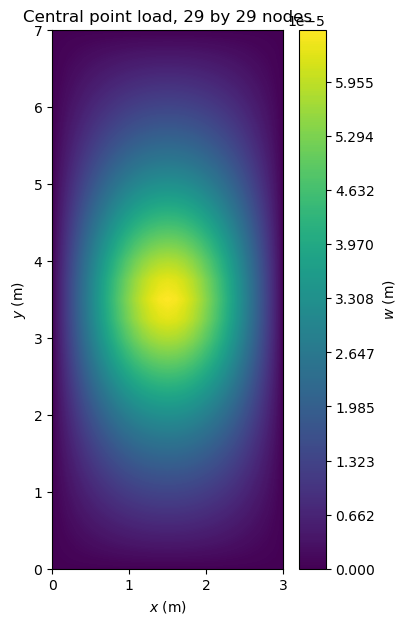

In [12]:
plt.figure(figsize=(4, 7))
plt.gca().set_aspect('equal')
levels = np.linspace(w.min(), w.max(), 300)
plt.contourf(xmesh, ymesh, w, levels=levels)
plt.colorbar(label='$w$ (m)')
plt.xlabel('$x$ (m)')
plt.ylabel('$y$ (m)')
plt.title('Central point load, 29 by 29 nodes')
plt.show()

## References

1. Timoshenko, S., and Woinowsky-Krieger, S., *Theory of Plates and Shells*, 2nd ed., McGraw-Hill, New York, 1959.